# Laboratory 06. Test a candidate change map

**Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.**

This is a complete worked laboratory. Run every cell in order, then carry out the investigations. The default data are synthetic. Consult the matching lecture and [assessment brief](../ASSESSMENT.md).

In [1]:
# Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.
from pathlib import Path
import sys, subprocess
# Local runs discover the checkout. Colab fetches it only if it is absent.
roots = [Path.cwd(), *Path.cwd().parents, Path('/content/satellitedatahscourse')]
root = next((p for p in roots if (p/'python'/'eo_course.py').exists()), None)
if root is None:
    if 'google.colab' not in sys.modules:
        raise RuntimeError('Open this notebook inside the course repository.')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'requests', 'rasterio', 'scikit-learn'], check=True)
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/caribbeanai/satellitedatahscourse.git', '/content/satellitedatahscourse'], check=True)
    root = Path('/content/satellitedatahscourse')
sys.path.insert(0, str(root/'python'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eo_course as eo
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.facecolor': 'white'})
print(eo.CREDIT)
print('Default data: SYNTHETIC teaching examples, not observations of Jamaica.')


Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.
Default data: SYNTHETIC teaching examples, not observations of Jamaica.


## 1. Build a known synthetic change
 We create a before image, lower the index in a known rectangle, add noise and remove some after observations. Knowing the synthetic truth lets us test the algorithm. It does not validate the method on a real hurricane.

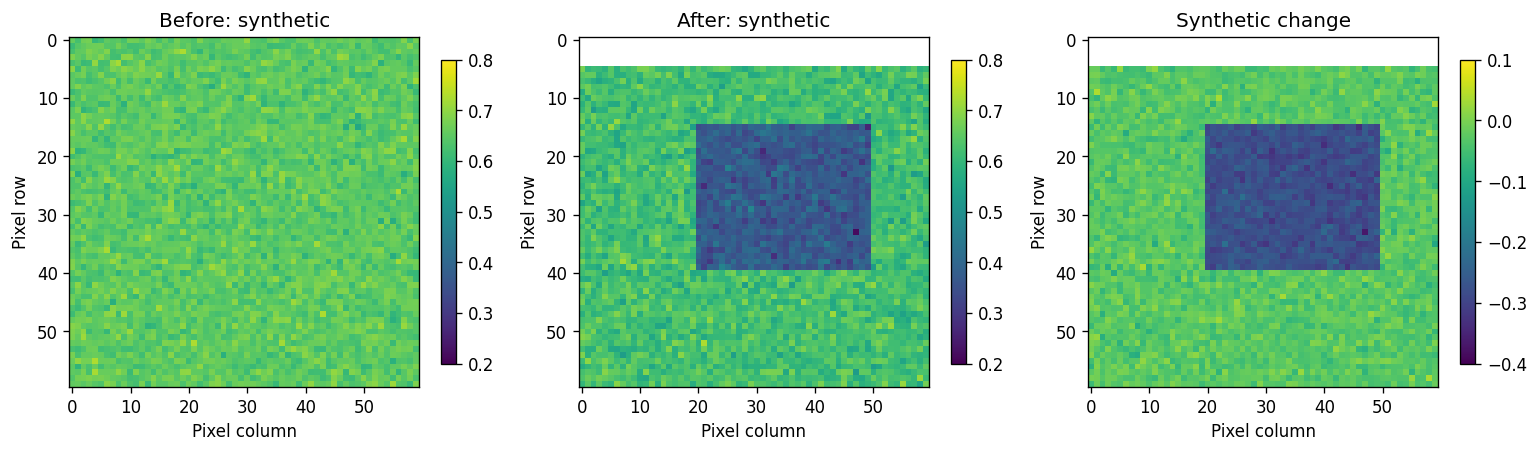

In [2]:
rng=np.random.default_rng(42)
before=np.full((60,60),.65)+rng.normal(0,.025,(60,60))
truth=np.zeros((60,60),dtype=bool);truth[15:40,20:50]=True
after=before-.03+rng.normal(0,.02,before.shape)
after[truth]-=.25
after[:5,:]=np.nan
result=eo.changed_area(before,after,threshold=-.2)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,a,title in zip(axes,[before,after,result['delta']],['Before: synthetic','After: synthetic','Synthetic change']):
    im=ax.imshow(a, vmin=-.4 if title=='Synthetic change' else .2, vmax=.1 if title=='Synthetic change' else .8);ax.set_title(title);ax.set_xlabel('Pixel column');ax.set_ylabel('Pixel row');fig.colorbar(im,ax=ax,shrink=.7)
plt.tight_layout();plt.show()

## 2. Threshold sensitivity and reference labels
 Candidate area depends on the threshold. Because this toy example has reference labels, we can calculate precision and recall among observed pixels. In a live project you would need an independent labelled sample. Unknown pixels are outside these scores.

In [3]:
sensitivity=[]
for threshold in [-.1,-.2,-.3]:
    r=eo.changed_area(before,after,threshold)
    observed=np.isfinite(r['delta']);pred=(r['delta']<threshold)&observed
    tp=np.sum(pred&truth);fp=np.sum(pred&~truth);fn=np.sum(~pred&truth&observed)
    sensitivity.append({k:r[k] for k in ['threshold','candidate_ha','observed_ha','unknown_ha']} |
                       {'precision':tp/(tp+fp) if tp+fp else np.nan,
                        'recall':tp/(tp+fn) if tp+fn else np.nan})
sensitivity=pd.DataFrame(sensitivity);display(sensitivity)
assert sensitivity.candidate_ha.is_monotonic_decreasing

   threshold  candidate_ha  observed_ha  unknown_ha  precision  recall
0       -0.1          30.0        132.0        12.0        1.0    1.00
1       -0.2          30.0        132.0        12.0        1.0    1.00
2       -0.3           4.2        132.0        12.0        1.0    0.14

## 3. A control contrast
 Assume this separate synthetic control experiences a seasonal decrease of about 0.03. Compute a difference of changes. Explain what assumptions you would need before calling this a causal estimate in an observed study.

In [4]:
control_before=np.full((60,60),.62)
control_after=control_before-.03+rng.normal(0,.02,(60,60))
treated_change=np.nanmean(after[truth]-before[truth])
control_change=np.mean(control_after-control_before)
contrast=treated_change-control_change
print({'synthetic_treated_change':treated_change,
       'synthetic_control_change':control_change,'synthetic_contrast':contrast})

{'synthetic_treated_change': np.float64(-0.27942721025626793), 'synthetic_control_change': np.float64(-0.030579127621727216), 'synthetic_contrast': np.float64(-0.24884808263454072)}


## 4. Resample spatial blocks
 The helper retains only fully observed, equally sized blocks. This changes the population when coverage is missing. Compare block sizes and report how many are retained. The interval describes this teaching resampling procedure; it excludes systematic measurement and attribution errors.

In [5]:
rows=[]
for block in [5,10,15]:
    interval=eo.block_bootstrap_mean(result['delta'],block=block,repeats=500)
    kept=sum(np.isfinite(result['delta'][r:r+block,c:c+block]).all()
             for r in range(0,60,block) for c in range(0,60,block))
    rows.append({'block_pixels':block,'fully_observed_blocks':kept,
                 'lower':interval[0],'upper':interval[1]})
display(pd.DataFrame(rows))

   block_pixels  fully_observed_blocks     lower     upper
0             5                    132 -0.106309 -0.068401
1            10                     30 -0.133550 -0.058382
2            15                     12 -0.148818 -0.058594

## 5. Your investigation and output
 Change the synthetic loss from 0.25 to 0.12 and repeat. Which threshold misses most known changes? Move the missing strip across the affected rectangle and explain how observed eligible area changes. For a real case, add an independent validation plan and a quiet-year comparison without calling the latter a false-positive rate.

In [6]:
out=root/'outputs'/'week2';out.mkdir(parents=True,exist_ok=True)
sensitivity.to_csv(out/'synthetic_threshold_sensitivity.csv',index=False)
eo.write_manifest(out/'manifest.json','synthetic',{'generator':'laboratory 06'},
                  {'seed':42,'pixel_metres':20,'thresholds':[-.1,-.2,-.3]},
                  [out/'synthetic_threshold_sensitivity.csv'])
print('Saved synthetic sensitivity and manifest.')

Saved synthetic sensitivity and manifest.


## Before submitting

Restart the kernel and run all cells. Label synthetic and observed outputs separately. Include the source, dates, units, quality policy and unknown coverage in captions. See [verified sources](../SOURCES.md) and the [instructor guide](../instructor/GUIDE.md).

Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.